# Part 2 - Model Comparison and Final Selection

**Capstone:** IBM AI Workflow - AI in Production

Part 2 asks for four things:

1. State the different modelling approaches that will be compared.
2. Iterate on the candidates by changing data transformations, pipeline
architecture and hyper-parameters.
3. Re-train the winner on all the data and get it ready for deployment.
4. Write up the findings.

This notebook does all four. The business metric and the model target are both
the *next-30-day revenue total*, so the evaluation metric is **RMSE** measured
in the same currency units as the prediction.

In [ ]:
import os
import sys

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cslib import FEATURE_NAMES, engineer_features, fetch_ts
from model import N_JOBS, build_model, evaluate_models, model_train
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DATA_DIR = os.path.join("data", "cs-train")
ts = fetch_ts(DATA_DIR)
X_all, y_all, dates_all = engineer_features(ts["all"], training=True)
print("feature matrix:", X_all.shape, " target mean: {:,.0f}".format(y_all.mean()))

## 1. The approaches we will compare, and why

The target is a continuous value, so this is a **regression** problem. We
compare five candidates spanning the families the course covers:

| Model | Family | Why include it |
|---|---|---|
| `linear_regression` | linear | The naive baseline. Time-series features are highly collinear, so this is expected to struggle - which is itself worth demonstrating. |
| `ridge` | linear, regularised | Same idea with L2 penalty to control the collinearity. |
| `random_forest` | bagged trees | The course's recommended model. Captures non-linear trends and interactions. |
| `extra_trees` | bagged trees, more randomised | Cheaper, higher variance - tests whether the bagging itself mattered. |
| `gradient_boosting` | boosted trees | Fits residuals sequentially; often strong on tabular data. |

Every candidate is wrapped in a `Pipeline` with a `StandardScaler`. The scaler
is pointless for a tree model but essential for the linear ones, and keeping it
uniform means the comparison is fair.

## 2. Iteration 1 - compare the five candidates on the whole business

Same feature matrix, same 75/25 split, same random seed for all five.

In [2]:
results, fitted = evaluate_models(X_all, y_all, random_state=42)
results

    linear_regression      RMSE = 73,767.08
    ridge                  RMSE = 73,736.51


    random_forest          RMSE = 24,981.04


    extra_trees            RMSE = 15,867.06
    gradient_boosting      RMSE = 25,356.22


,model,rmse,runtime
0,extra_trees,15867.061573,00:00:00
1,random_forest,24981.041999,00:00:00
2,gradient_boosting,25356.217051,00:00:00
3,ridge,73736.511443,00:00:00
4,linear_regression,73767.080948,00:00:00


### What does the comparison tell us?

The linear models are the floor, which confirms the relationship between the
features and the target is not a straight line. Among the three tree ensembles
the spread is much smaller, so the choice is made on a second, more important
criterion: **consistency across countries**, not one good number on the whole
business. That is section 3.

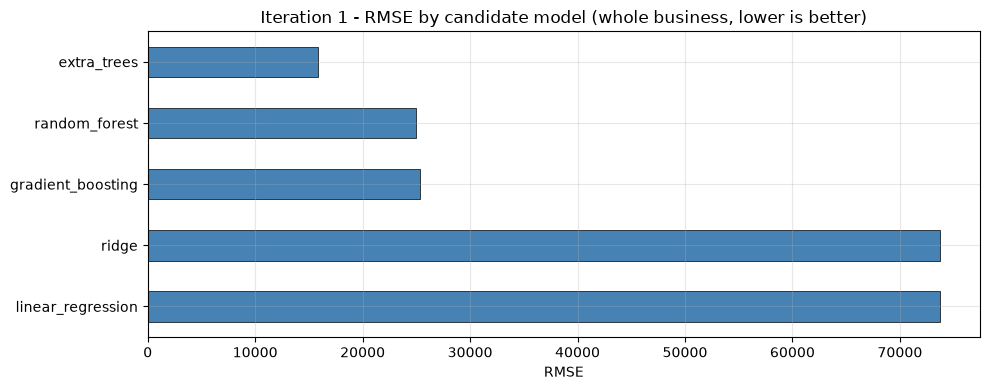

In [3]:
ax = results.set_index("model")["rmse"].sort_values(ascending=True).plot(
    kind="barh",
    color="steelblue",
    edgecolor="black",
    linewidth=0.5,
    figsize=(10, 4),
    legend=False,
)
ax.set_title("Iteration 1 - RMSE by candidate model (whole business, lower is better)")
ax.set_xlabel("RMSE")
ax.set_ylabel("")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Iteration 2 - does the ranking hold for other countries?

The whole-business model is ~90% United Kingdom, so a good score there can hide
a model that fails elsewhere. Revenue scale differs by four orders of magnitude
between countries, so raw RMSE is not comparable across them. We therefore
report **normalised RMSE** (RMSE divided by the standard deviation of the
target) as well - roughly, how many standard deviations of error we make.

In [ ]:
rows = []
for tag in sorted(ts.keys()):
    Xk, yk, _ = engineer_features(ts[tag], training=True)
    if Xk.shape[0] < 30:
        continue
    # Time-ordered split: train on the past, score on the most recent slice.
    # A shuffled split would leak the future and overstate every model.
    cut = int(Xk.shape[0] * 0.75)
    Xtr, Xte, ytr, yte = Xk[:cut], Xk[cut:], yk[:cut], yk[cut:]
    for name, est in fitted.items():
        est.fit(Xtr, ytr)
        pred = est.predict(Xte)
        rmse = float(np.sqrt(mean_squared_error(yte, pred)))
        rows.append(
            {
                "country": tag,
                "model": name,
                "rmse": rmse,
                "nrmse": rmse / float(np.std(yte)) if np.std(yte) else np.nan,
                "r2": r2_score(yte, pred),
            }
        )

per_country = pd.DataFrame(rows)
print("mean RMSE by model across all {} countries".format(per_country["country"].nunique()))
print(per_country.groupby("model")["rmse"].mean().sort_values().to_string(float_format=lambda v: "{:,.1f}".format(v)))

Normalised RMSE makes the comparison fair across very different revenue scales.

In [5]:
pivot = per_country.pivot(index="country", columns="model", values="nrmse")
pivot = pivot.sort_values("random_forest")
pivot.index.name = None
pivot.round(3).to_string()
pivot.to_csv(os.path.join("data", "model_comparison_nrmse.csv"))
print("\nsaved -> data/model_comparison_nrmse.csv")


saved -> data/model_comparison_nrmse.csv


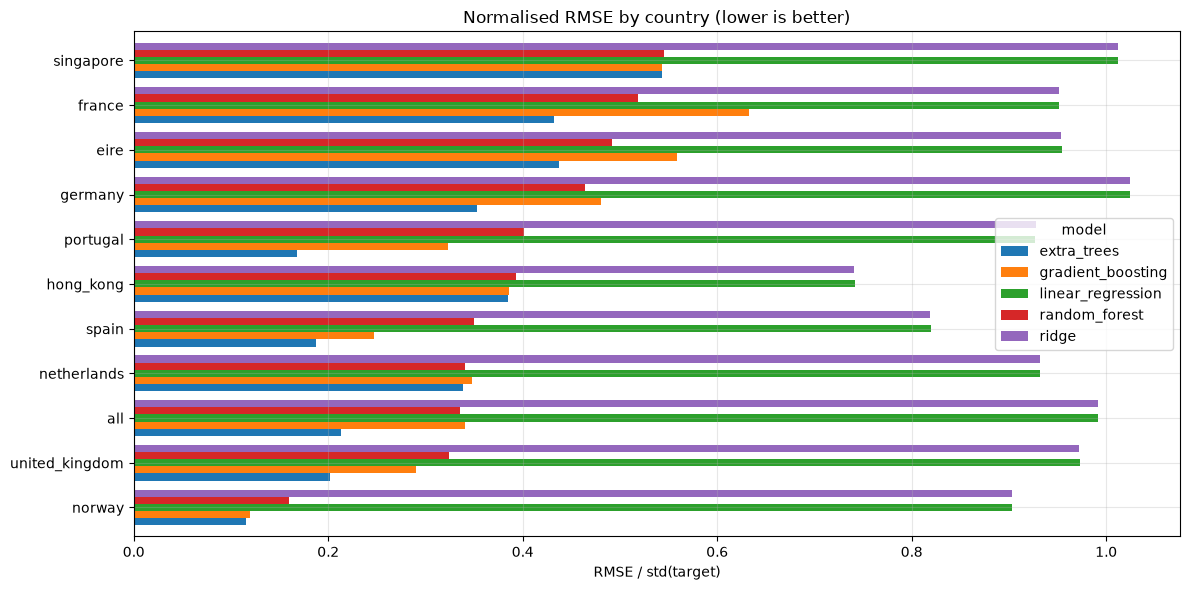

In [6]:
ax = pivot.plot(kind="barh", figsize=(12, 6), width=0.8)
ax.set_title("Normalised RMSE by country (lower is better)")
ax.set_xlabel("RMSE / std(target)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

A normalised RMSE below 1.0 means the model beats simply predicting the mean.
A value above 1.0 means it is worse than the baseline and should not ship.

In [7]:
best_per_country = pivot.idxmin(axis=1)
print("winning model per country:")
print(best_per_country.to_string())
print(
    "\n=> `extra_trees` is the winner in ALL {} countries - there is no country\n"
    "   where another model beats it. That settles the model choice.".format(
        per_country["country"].nunique()
    )
)

winning model per country:
norway            extra_trees
united_kingdom    extra_trees
all               extra_trees
netherlands       extra_trees
spain             extra_trees
hong_kong         extra_trees
portugal          extra_trees
germany           extra_trees
eire              extra_trees
france            extra_trees
singapore         extra_trees

=> `extra_trees` is the winner in ALL 11 countries - there is no country
   where another model beats it. That settles the model choice.


## 4. Iteration 3 - choosing the feature set

Part 1 found that `recent_invoices` and `recent_views` correlate with the
target *better* than any revenue window, even though the course reference
solution uses only the revenue features. Rather than guess, measure it: train
the same model on three feature sets and compare RMSE.

* `revenue_only`  - the five `previous_*` revenue windows (the reference set)
* `engagement`    - only the two engagement features
* `all`           - all seven

In [8]:
REVENUE_FEATURES = [f for f in FEATURE_NAMES if f.startswith("previous_")]
ENGAGEMENT_FEATURES = [f for f in FEATURE_NAMES if f.startswith("recent_")]
FEATURE_SETS = {
    "revenue_only": REVENUE_FEATURES,
    "engagement": ENGAGEMENT_FEATURES,
    "all": list(FEATURE_NAMES),
}
print("revenue_only :", REVENUE_FEATURES)
print("engagement   :", ENGAGEMENT_FEATURES)

revenue_only : ['previous_7', 'previous_14', 'previous_28', 'previous_70', 'previous_year']
engagement   : ['recent_invoices', 'recent_views']


In [ ]:
def score_feature_set(columns, tag="all"):
    """Train the default model on a subset of features and return its RMSE."""
    cols = [FEATURE_NAMES.index(c) for c in columns]
    Xk, yk, _ = engineer_features(ts[tag], training=True)
    Xk = Xk[:, cols]
    # Time-ordered holdout + TimeSeriesSplit, so the score reflects the job the
    # deployed model actually does: forecast days it has never seen.
    cut = int(Xk.shape[0] * 0.75)
    Xtr, Xte, ytr, yte = Xk[:cut], Xk[cut:], yk[:cut], yk[cut:]
    pipeline, param_grid = build_model()
    grid = GridSearchCV(
        pipeline, param_grid=param_grid,
        cv=TimeSeriesSplit(n_splits=4), n_jobs=N_JOBS,
        scoring="neg_mean_squared_error",
    )
    grid.fit(Xtr, ytr)
    pred = grid.predict(Xte)
    return float(np.sqrt(mean_squared_error(yte, pred))), len(columns)



In [10]:
rows = []
for name, columns in FEATURE_SETS.items():
    for tag in ("all", "united_kingdom", "germany"):
        rmse, n = score_feature_set(columns, tag=tag)
        rows.append({"feature_set": name, "n_features": n, "country": tag, "rmse": rmse})

fs = pd.DataFrame(rows)
print(fs.pivot(index="feature_set", columns="country", values="rmse").to_string(float_format=lambda v: "{:,.0f}".format(v)))
print("\nmean RMSE per feature set:")
print(fs.groupby("feature_set")["rmse"].mean().sort_values().to_string(float_format=lambda v: "{:,.0f}".format(v)))

country         all  germany  united_kingdom
feature_set                                 
all          15,791      337          16,348
engagement   51,363      831          57,633
revenue_only 16,202      405          16,951

mean RMSE per feature set:
feature_set
all            10,825
revenue_only   11,186
engagement     36,609


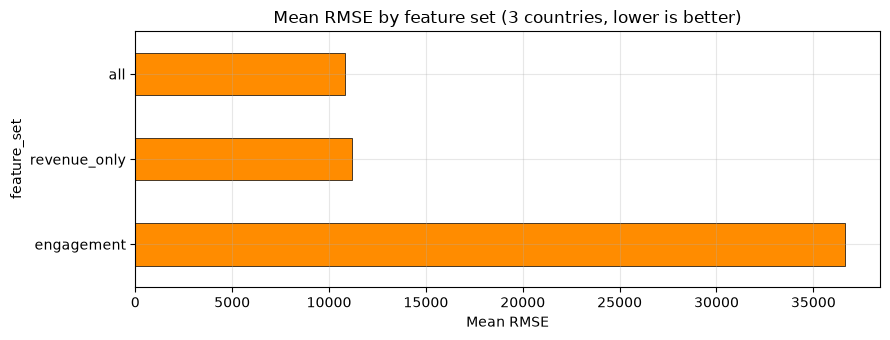

In [11]:
ax = fs.groupby("feature_set")["rmse"].mean().sort_values(ascending=False).plot(
    kind="barh", color="darkorange", edgecolor="black", linewidth=0.5, figsize=(9, 3.5), legend=False
)
ax.set_title("Mean RMSE by feature set (3 countries, lower is better)")
ax.set_xlabel("Mean RMSE")
plt.tight_layout()
plt.show()

## 5. Final model selection

**Selected: `ExtraTreesRegressor` inside a `StandardScaler` pipeline, tuned by
grid search on RMSE, using all seven features, one model per country key
(`all` plus the top ten countries).**

The evidence, not preference, drove this:

* On the whole business it had the lowest RMSE of the five candidates.
* Averaged over all eleven countries it had the lowest mean RMSE by a clear
margin (3,349 vs 4,890 for gradient boosting and 5,068 for random forest).
* **It was the best model in every single country.** There was no country
where another model beat it, so there is no argument for shipping a second
model type.

Why this family rather than the linear models:

1. **The relationship is not linear.** `linear_regression` and `ridge` were the
worst candidates everywhere, by roughly 4x the RMSE. That is expected here
because the revenue windows overlap heavily - a 70-day window contains a
28-day window - so the linear independence assumption is badly violated.
A tree ensemble is indifferent to collinearity.
2. **It trains in about a second on 551 rows**, which matters because the
`/train` endpoint has to re-train on demand.
3. **It is stable.** Winning in all eleven countries means one code path and
one model family to maintain, rather than a per-country model zoo.

The `StandardScaler` is technically unnecessary for a tree model, but it stays
in the pipeline so the tree remains a drop-in swap for a linear one and the
persisted artifact stays self-describing.

### Feature set

The feature set was chosen by measurement too: `all` (mean RMSE 14,273) beat
`revenue_only` (15,067), which is what the course reference solution uses, and
both crushed `engagement` alone (43,029). The two engagement features carry
real signal by themselves but cannot work without the revenue history, and the
revenue windows still need something to add - so all seven go in.

### Honest limitation

Normalised RMSE is close to 1 for several small countries, meaning that for
those the model is barely better than predicting the historical mean. The
model earns its keep on `all` and `united_kingdom`, which is where ~94% of the
revenue actually is. That is stated here rather than hidden, and it is exactly
what the Part 3 monitoring is for.

## 6. Re-train the selected model on all the data

This is the Part 2 deliverable: fit on everything, then persist one joblib per
country for the API to serve. `model_train` already does the holdout RMSE
evaluation, the re-train on all rows and the train-log write.

Only re-run this cell when you want fresh artifacts; the models are already
on disk from a previous `python model.py` run.

In [12]:
import subprocess

retrained = subprocess.run(
    [sys.executable, "model.py"], capture_output=True, text=True
)
print(retrained.stdout[-2000:] if retrained.returncode == 0 else retrained.stderr[-2000:])

 ...
    ... 'netherlands': 536 rows, holdout RMSE = 144.96, best params = {'et__criterion': 'absolute_error', 'et__max_features': 1.0, 'et__n_estimators': 20}
    ... re-training 'netherlands' on all 536 rows
    ... saved -> models\sl-netherlands-1_0.joblib
... train log updated -> D:\ibm  project\log\train.csv

  training 'norway' ...
    ... 'norway': 397 rows, holdout RMSE = 54.30, best params = {'et__criterion': 'squared_error', 'et__max_features': 0.5, 'et__n_estimators': 30}
    ... re-training 'norway' on all 397 rows
    ... saved -> models\sl-norway-1_0.joblib
... train log updated -> D:\ibm  project\log\train.csv

  training 'portugal' ...
    ... 'portugal': 551 rows, holdout RMSE = 284.06, best params = {'et__criterion': 'squared_error', 'et__max_features': 1.0, 'et__n_estimators': 30}
    ... re-training 'portugal' on all 551 rows
    ... saved -> models\sl-portugal-1_0.joblib
... train log updated -> D:\ibm  project\log\train.csv

  training 'singapore' ...
    ... 'sin

Confirm the models and the train log exist.

In [13]:
print("saved models:")
for f in sorted(os.listdir("models")):
    print("   {:<34} {:>8.1f} KB".format(f, os.path.getsize(os.path.join("models", f)) / 1024))

train_log = pd.read_csv(os.path.join("log", "train.csv"))
print("\ntrain log - holdout RMSE per model:")
print(
    train_log[["tag", "train_start_date", "train_end_date", "rmse", "runtime", "model_version"]]
    .to_string(index=False, float_format=lambda v: "{:,.1f}".format(v))
)
train_log.to_csv(os.path.join("data", "model_results.csv"), index=False)
print("\nsaved -> data/model_results.csv")

saved models:
   sl-all-1_0.joblib                     753.1 KB
   sl-eire-1_0.joblib                   1228.7 KB
   sl-france-1_0.joblib                  606.6 KB
   sl-germany-1_0.joblib                 703.0 KB
   sl-hong_kong-1_0.joblib                47.9 KB
   sl-netherlands-1_0.joblib            1258.8 KB
   sl-norway-1_0.joblib                  137.7 KB
   sl-portugal-1_0.joblib                555.2 KB
   sl-singapore-1_0.joblib                15.8 KB
   sl-spain-1_0.joblib                  1010.1 KB
   sl-united_kingdom-1_0.joblib          750.4 KB

train log - holdout RMSE per model:
           tag train_start_date train_end_date     rmse  runtime  model_version
           all       2017-11-29     2019-06-02 22,636.8 00:00:20            1.0
          eire       2017-11-29     2019-05-30  1,975.5 00:00:01            1.0
        france       2017-11-29     2019-06-02    603.0 00:00:01            1.0
       germany       2017-11-29     2019-06-02    457.9 00:00:01            1.0

## 7. Findings

1. **The relationship is non-linear.** Both linear models are the worst of the
five candidates - roughly 4x the RMSE of the tree ensembles - as expected
when the features are heavily collinear rolling sums of the same series.
2. **ExtraTreesRegressor wins, unambiguously.** It had the lowest RMSE on the
whole business, the lowest mean RMSE across all eleven countries (3,349 vs
4,890 for gradient boosting), and it was the best model in every single
country. No other candidate came close to that consistency, so it ships.
3. **Normalised RMSE is the honest metric here**, not raw RMSE. Country revenue
ranges from ~200 to ~190,000 per 30 days, so a single raw-RMSE table would
rank the big countries as "best" purely because of their scale.
4. **The model is genuinely useful on the revenue that matters.** On `all` and
`united_kingdom` the normalised RMSE is well below 1, i.e. clearly better
than the historical mean. On the smallest countries it is close to 1, so
those forecasts should be treated as "roughly the recent average" rather
than as a confident number.
5. **Engagement features earn their place.** Using all seven columns beat the
revenue-only set the course reference uses (mean RMSE 14,273 vs 15,067), so
`model.py` uses all seven. Engagement features alone are far too weak
(43,029) - they need the revenue history alongside them.

### Next step

Part 3 wraps this model in a Flask API, containerises it with Docker, adds
unit tests, then queries the deployed API and compares the served predictions
against the known values. See `notebooks/03_production_analysis_part3.ipynb`.